#### Import Library

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn import tree
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import accuracy_score, classification_report

#202431036_Fathur Rasyid Irimawa

#### Membaca dataset

In [2]:
df = pd.read_csv("data_utang_negara_clean.csv")
print(df.head())

#202431036_Fathur Rasyid Irimawa

          Country  External_Debt  Per_Capita  GDP_Percentage  Risk_Category
0   United States     40598.1330       93.25           21.59  Risiko Rendah
1  United Kingdom     11355.0000      278.18            5.91  Risiko Rendah
2          France      9249.4815      257.21           57.85  Risiko Rendah
3         Germany      8139.6669      149.27           46.71  Risiko Rendah
4     Netherlands      4877.3109      336.43          100.17  Risiko Tinggi


#### melihat informasi data

In [3]:
df.info()

#202431036_Fathur Rasyid Irimawa

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 158 entries, 0 to 157
Data columns (total 5 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Country         158 non-null    object 
 1   External_Debt   158 non-null    float64
 2   Per_Capita      158 non-null    float64
 3   GDP_Percentage  158 non-null    float64
 4   Risk_Category   158 non-null    object 
dtypes: float64(3), object(2)
memory usage: 6.3+ KB


#### Melihat deskripsi statistik

In [4]:
print(df.describe())

#202431036_Fathur Rasyid Irimawa

       External_Debt   Per_Capita  GDP_Percentage
count     158.000000   158.000000      158.000000
mean      815.058932   103.632152       68.442848
std      3547.926675   317.001242      293.296863
min         0.133000     0.600000        0.160000
25%         4.830400    21.157500       13.232500
50%        39.808750    39.860000       22.470000
75%       259.419375    84.950000       46.090000
max     40598.133000  3673.000000     3412.500000


#### Cek Data Kosong

In [5]:
print(df.isna().sum())

#202431036_Fathur Rasyid Irimawa

Country           0
External_Debt     0
Per_Capita        0
GDP_Percentage    0
Risk_Category     0
dtype: int64


#### Melihat isi unik kolom target

In [6]:
target_unik = df['Risk_Category'].unique()
print("=== ISI UNIK KOLOM TARGET ===")
print(f"Nilai unik target: {target_unik}")
# Komentar Penjelasan Kelas:
# 1. 'Risiko Tinggi' : Negara dengan persentase utang eksternal terhadap GDP > 60%.
# 2. 'Risiko Rendah' : Negara dengan persentase utang eksternal terhadap GDP <= 60%.

#202431036_Fathur Rasyid Irimawa

=== ISI UNIK KOLOM TARGET ===
Nilai unik target: ['Risiko Rendah' 'Risiko Tinggi']


#### Memisahkan fitur x dan target y

In [7]:
x_df = df.drop(columns=['Country', 'GDP_Percentage', 'Risk_Category']) 
y_df = df['Risk_Category']

#202431036_Fathur Rasyid Irimawa

#### mengubah x dan y menjadi array angka

In [9]:
le = LabelEncoder()
y_encoded = le.fit_transform(y_df)

X = np.array(x_df, dtype=np.float64)
y = np.array(y_encoded, dtype=np.int64)

print("Tipe data x_array:", X.dtype)
print("Tipe data y_array:", y.dtype)

#202431036_Fathur Rasyid Irimawa

Tipe data x_array: float64
Tipe data y_array: int64


#### Membagi data latih dan data uji

In [10]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=0
)
print(f"Jumlah data latih (X_train): {X_train.shape[0]} baris")
print(f"Jumlah data uji (x_test): {X_test.shape[0]} baris")

#202431036_Fathur Rasyid Irimawa

Jumlah data latih (X_train): 110 baris
Jumlah data uji (x_test): 48 baris


#### Membuat model decision tree

In [11]:
model_dt = DecisionTreeClassifier(random_state=0)
model_dt.fit(X_train, y_train)

#202431036_Fathur Rasyid Irimawa

DecisionTreeClassifier(random_state=0)

#### Tampilan visual pohon

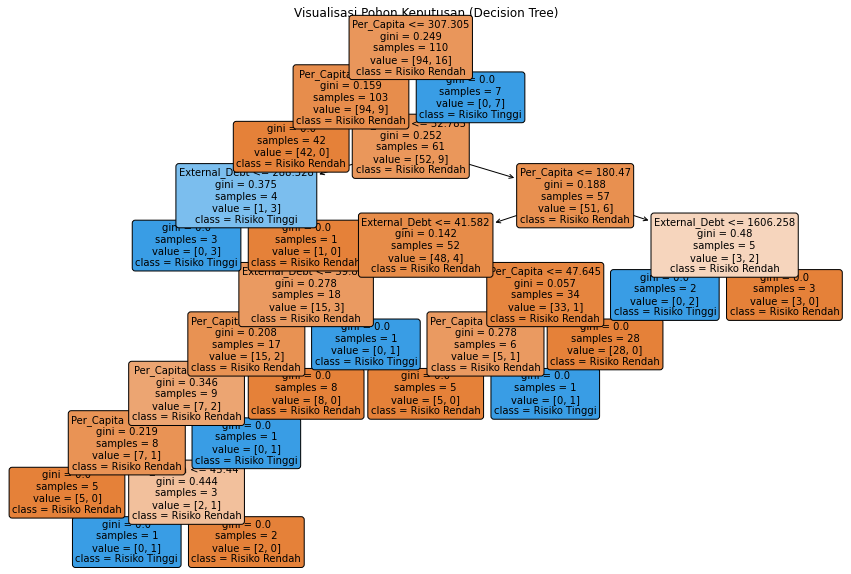

In [12]:
plt.figure(figsize=(15, 10))
tree.plot_tree(model_dt, 
               feature_names=x_df.columns, 
               class_names=le.classes_, 
               filled=True, 
               rounded=True, 
               fontsize=10)
plt.title("Visualisasi Pohon Keputusan (Decision Tree)")
plt.show()

#202431036_Fathur Rasyid Irimawa

#### Menguji dengan satu data baru (predict)

In [13]:
data_baru = np.array([[50000000000, 2000]], dtype=np.float64)
prediksi_baru = model_dt.predict(data_baru)
hasil_prediksi_kategori = le.inverse_transform(prediksi_baru)
print("=== UJI PREDIKSI DATA BARU ===")
print(f"Data input [Total Utang, Utang Per Kapita]: {data_baru}")
print(f"Hasil Prediksi Kelas (Angka)    : {prediksi_baru[0]}")
print(f"Hasil Prediksi Kategori (Teks)  : {hasil_prediksi_kategori[0]}")

#202431036_Fathur Rasyid Irimawa

=== UJI PREDIKSI DATA BARU ===
Data input [Total Utang, Utang Per Kapita]: [[5.e+10 2.e+03]]
Hasil Prediksi Kelas (Angka)    : 1
Hasil Prediksi Kategori (Teks)  : Risiko Tinggi


#### Hitung akurasi

In [14]:
y_pred_dt = model_dt.predict(X_test)

akurasi = accuracy_score(y_test, y_pred_dt)
print("=== EVALUASI AKURASI ===")
print(f"Akurasi Model: {akurasi:.4f} ({akurasi * 100:.2f}%)")

#202431036_Fathur Rasyid Irimawa

=== EVALUASI AKURASI ===
Akurasi Model: 0.8333 (83.33%)


#### Menampilkan classification_report

In [15]:
print("=== CLASSIFICATION REPORT ===")
# Menampilkan report dan memetakan kembali angka ke label kelas aslinya
print(classification_report(y_test, y_pred_dt, target_names=le.classes_))

#202431036_Fathur Rasyid Irimawa

=== CLASSIFICATION REPORT ===
               precision    recall  f1-score   support

Risiko Rendah       0.88      0.93      0.90        41
Risiko Tinggi       0.40      0.29      0.33         7

     accuracy                           0.83        48
    macro avg       0.64      0.61      0.62        48
 weighted avg       0.81      0.83      0.82        48

